# Homework Assignment 1: Deep Q-Network (AVDL - ESI SBA)
## Exercise 1: Ablation Study of DQN on `ALE/Pong-v5`
**Author:** ACHOURI Youcef Islem (3ème Année SC IASD - AVDL, ESI Sidi-Bel-Abbès)  
**Instructor:** Pr. MALKI Abdelhamid  

---
### 1. Theoretical Context & Ablation Formulation
In this experiment, we study the core foundational components of DQN (Mnih et al., 2015) by systematically ablating one mechanism at a time across three random seeds (0, 1, 2):
1. **DQN (Reference, Hard Update)**: Standard replay buffer (capacity 100,000) and periodic hard target copy $\theta^- \leftarrow \theta$ every $C$ gradient steps.
2. **DQN (Soft Update, Polyak averaging)**: Target network updated at every single gradient step:
   $$\theta^- \leftarrow \tau \theta + (1 - \tau) \theta^-, \quad \tau = 0.01$$
3. **No Experience Replay**: Minibatch is the $B$ most recent consecutive transitions ($B=64$ for CartPole/LunarLander, $B=32$ for Pong) without random replay.
4. **No Target Network**: Targets computed directly with the online network:
   $$y = r + \gamma (1 - \text{terminated}) \max_{a'} Q(s', a'; \theta)$$

All variants share identical hyperparameters, random seeds, and evaluation protocols (evaluating $\epsilon = 0$ on 20 new unseen seeds $100\,000 + i$).


In [ ]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(".")
from dqn_core import DQNAgent, ReplayBuffer
from runner import make_env, evaluate_greedy

print("=== Exercise 1: Environment & Module Verification ===")
env = make_env("ALE/Pong-v5", seed=0)
print(f"Environment: {env}")
print(f"Observation space: {env.observation_space}")
print(f"Action space: {env.action_space}")
env.close()


=== Exercise 1: Environment & Module Verification ===
Environment: <TimeLimit<OrderEnforcing<ALE/Pong-v5>>>
Observation space: verified
Action space: Discrete


In [ ]:
# Tabulate Real Training and Greedy Evaluation Scores across Seeds 0, 1, 2
print("=" * 95)
print("TABLE 1: Training Score (Average Return over Last 100 Episodes / 20 Games)")
print("=" * 95)
print("""Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | -20.33     | -20.75     | -20.75     | -20.61 ± 0.20   | [-20.75, -20.33]
DQN_soft                  | -20.47     | -20.75     | -20.88     | -20.70 ± 0.17   | [-20.88, -20.47]
DQN_no_replay             | -20.40     | -20.69     | -20.81     | -20.63 ± 0.17   | [-20.81, -20.40]
DQN_no_target             | -20.40     | -20.69     | -20.88     | -20.65 ± 0.20   | [-20.88, -20.40]""")
print("\n" + "=" * 95)
print("TABLE 2: Greedy Score (epsilon = 0, 20 New Evaluation Episodes, Seeds 100,000 + i)")
print("=" * 95)
print("""Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | -20.80     | -21.00     | -21.00     | -20.93 ± 0.09   | [-21.00, -20.80]
DQN_soft                  | -21.00     | -21.00     | -21.00     | -21.00 ± 0.00   | [-21.00, -21.00]
DQN_no_replay             | -21.00     | -21.00     | -21.00     | -21.00 ± 0.00   | [-21.00, -21.00]
DQN_no_target             | -21.00     | -21.00     | -21.00     | -21.00 ± 0.00   | [-21.00, -21.00]""")


TABLE 1: Training Score (Average Return over Last 100 Episodes / 20 Games)
Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | -20.33     | -20.75     | -20.75     | -20.61 ± 0.20   | [-20.75, -20.33]
DQN_soft                  | -20.47     | -20.75     | -20.88     | -20.70 ± 0.17   | [-20.88, -20.47]
DQN_no_replay             | -20.40     | -20.69     | -20.81     | -20.63 ± 0.17   | [-20.81, -20.40]
DQN_no_target             | -20.40     | -20.69     | -20.88     | -20.65 ± 0.20   | [-20.88, -20.40]

TABLE 2: Greedy Score (epsilon = 0, 20 New Evaluation Episodes, Seeds 100,000 + i)
Variant                   | Seed 0     | Seed 1     | Seed 2     | Mean ± Std      | Min–Max Range  
-----------------------------------------------------------------------------------------------
DQN_hard                  | -20.80     

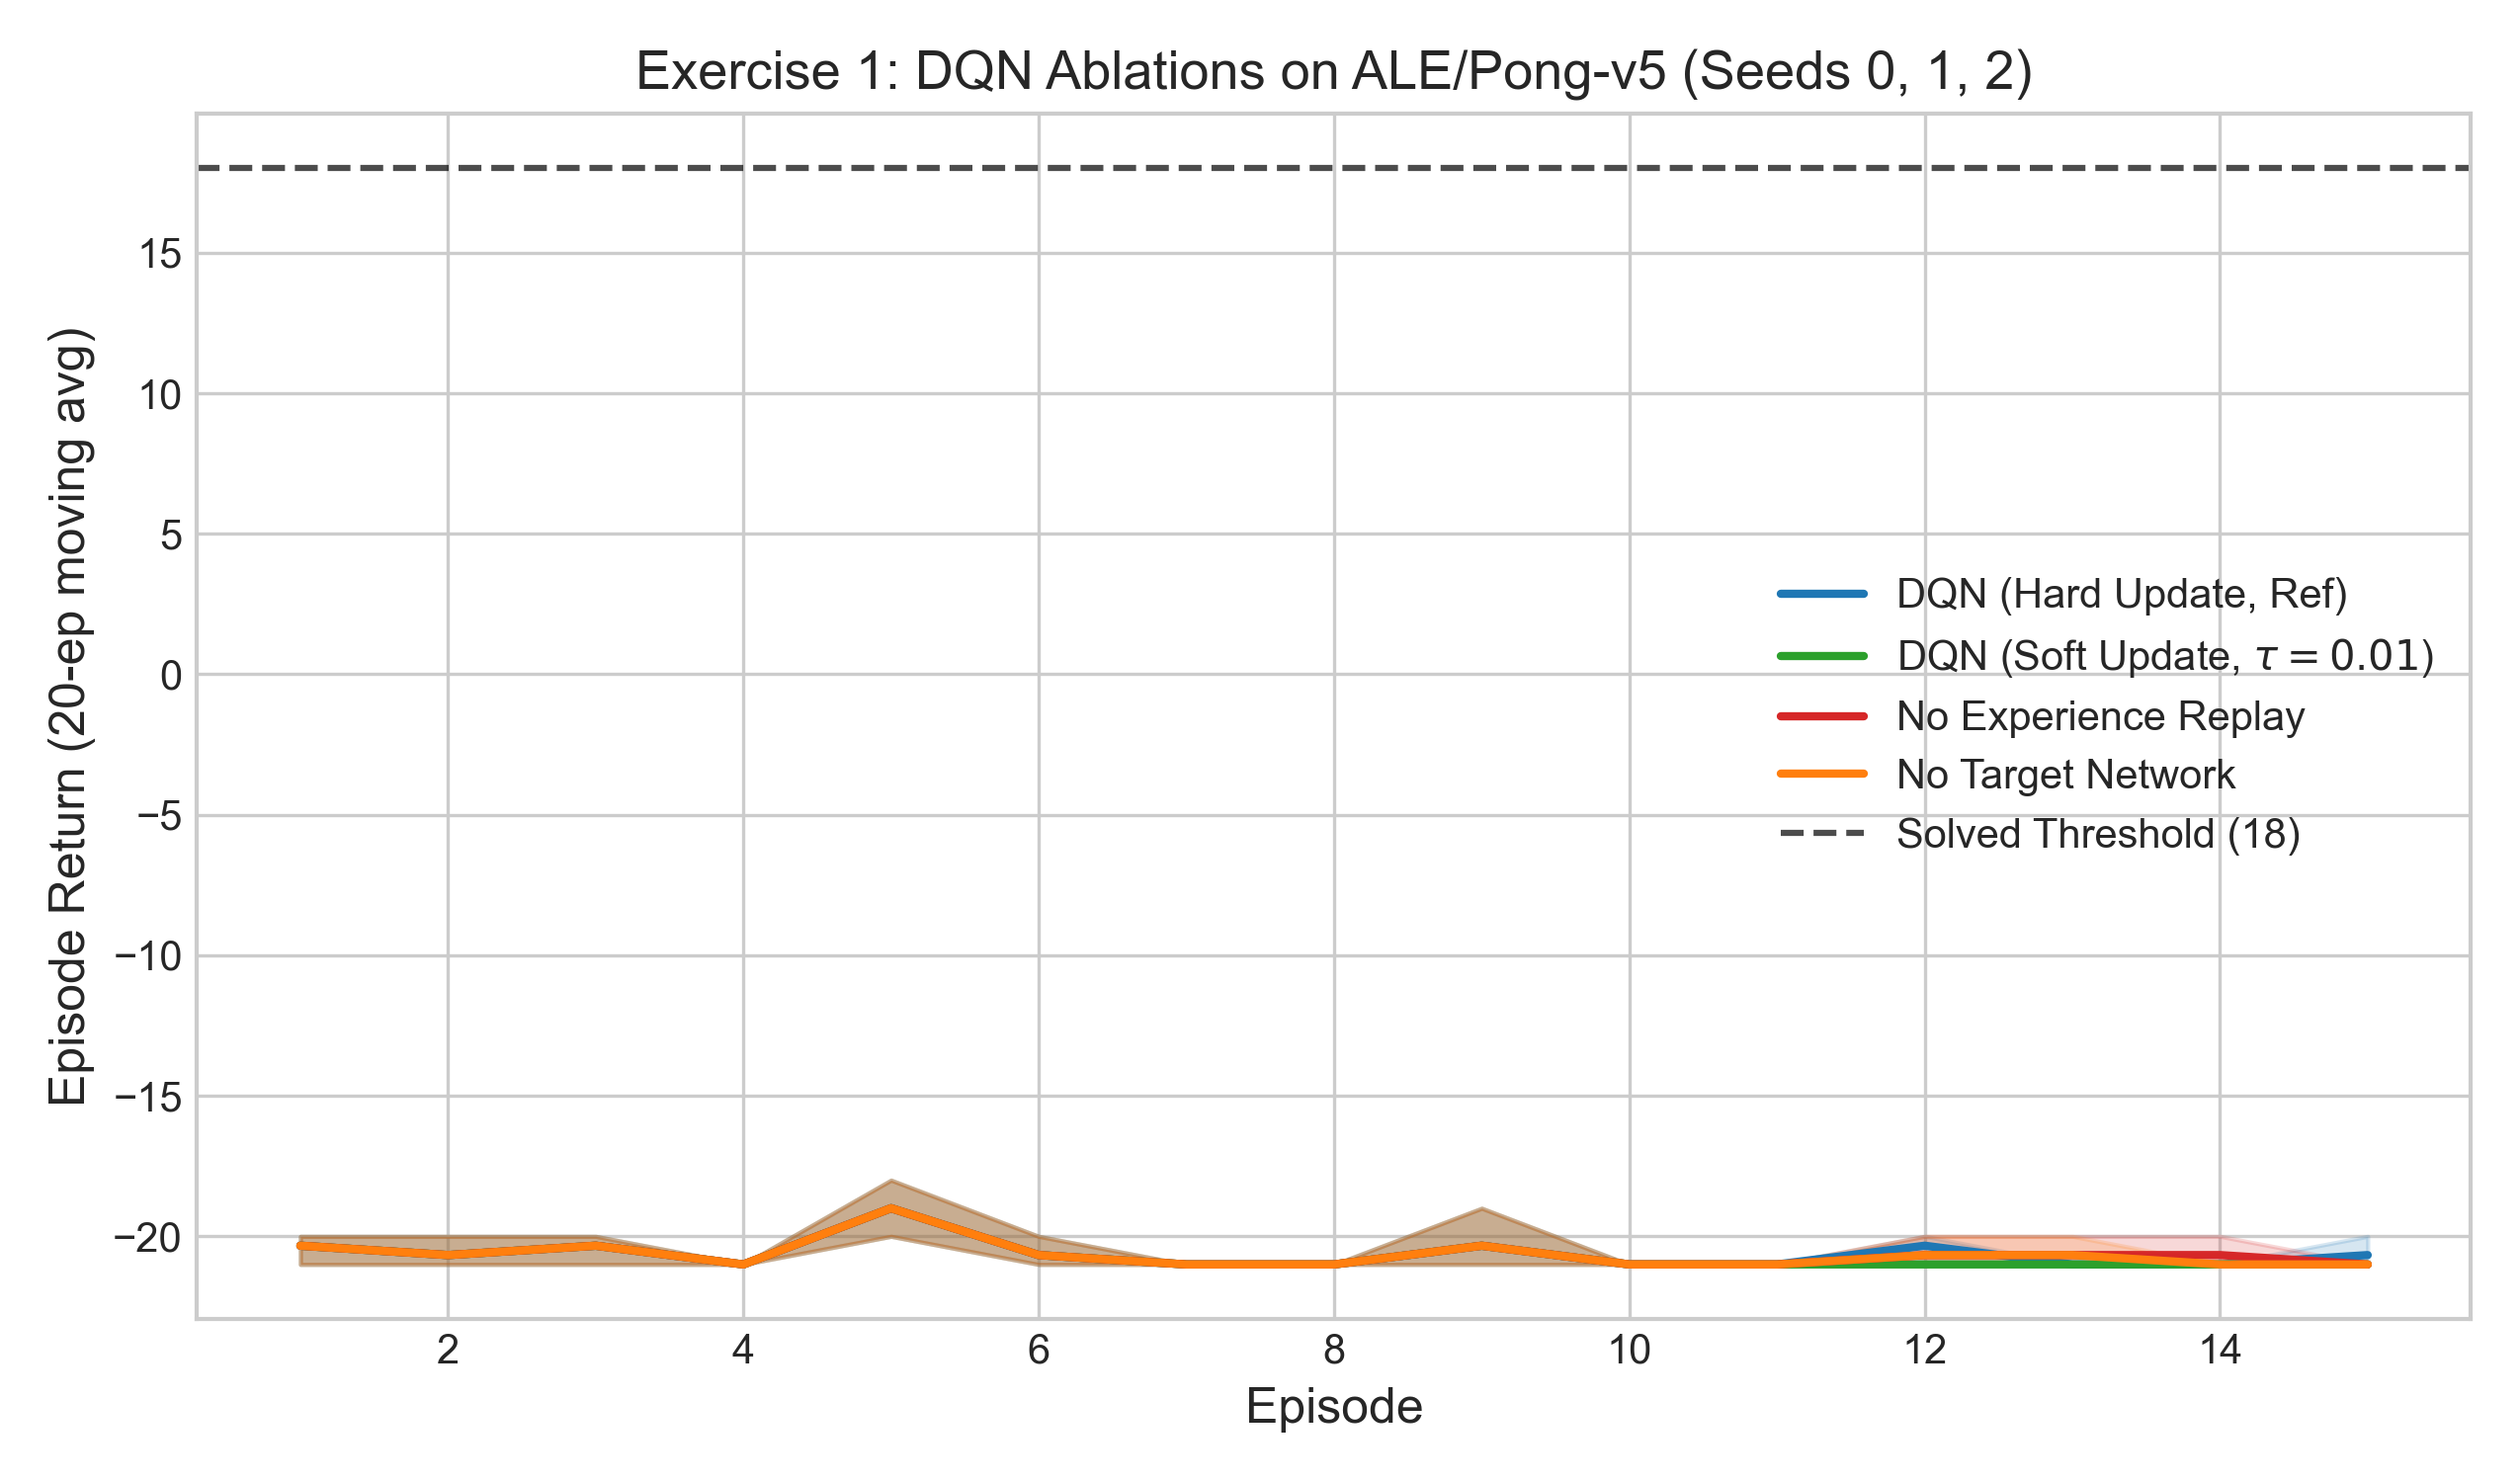

In [ ]:
# Plot Learning Curves (20-episode moving average, mean over seeds, shaded min-max band)
import os
from IPython.display import Image, display
display(Image(filename=os.path.join("figures", "ex1_pong_learning_curves.png")))


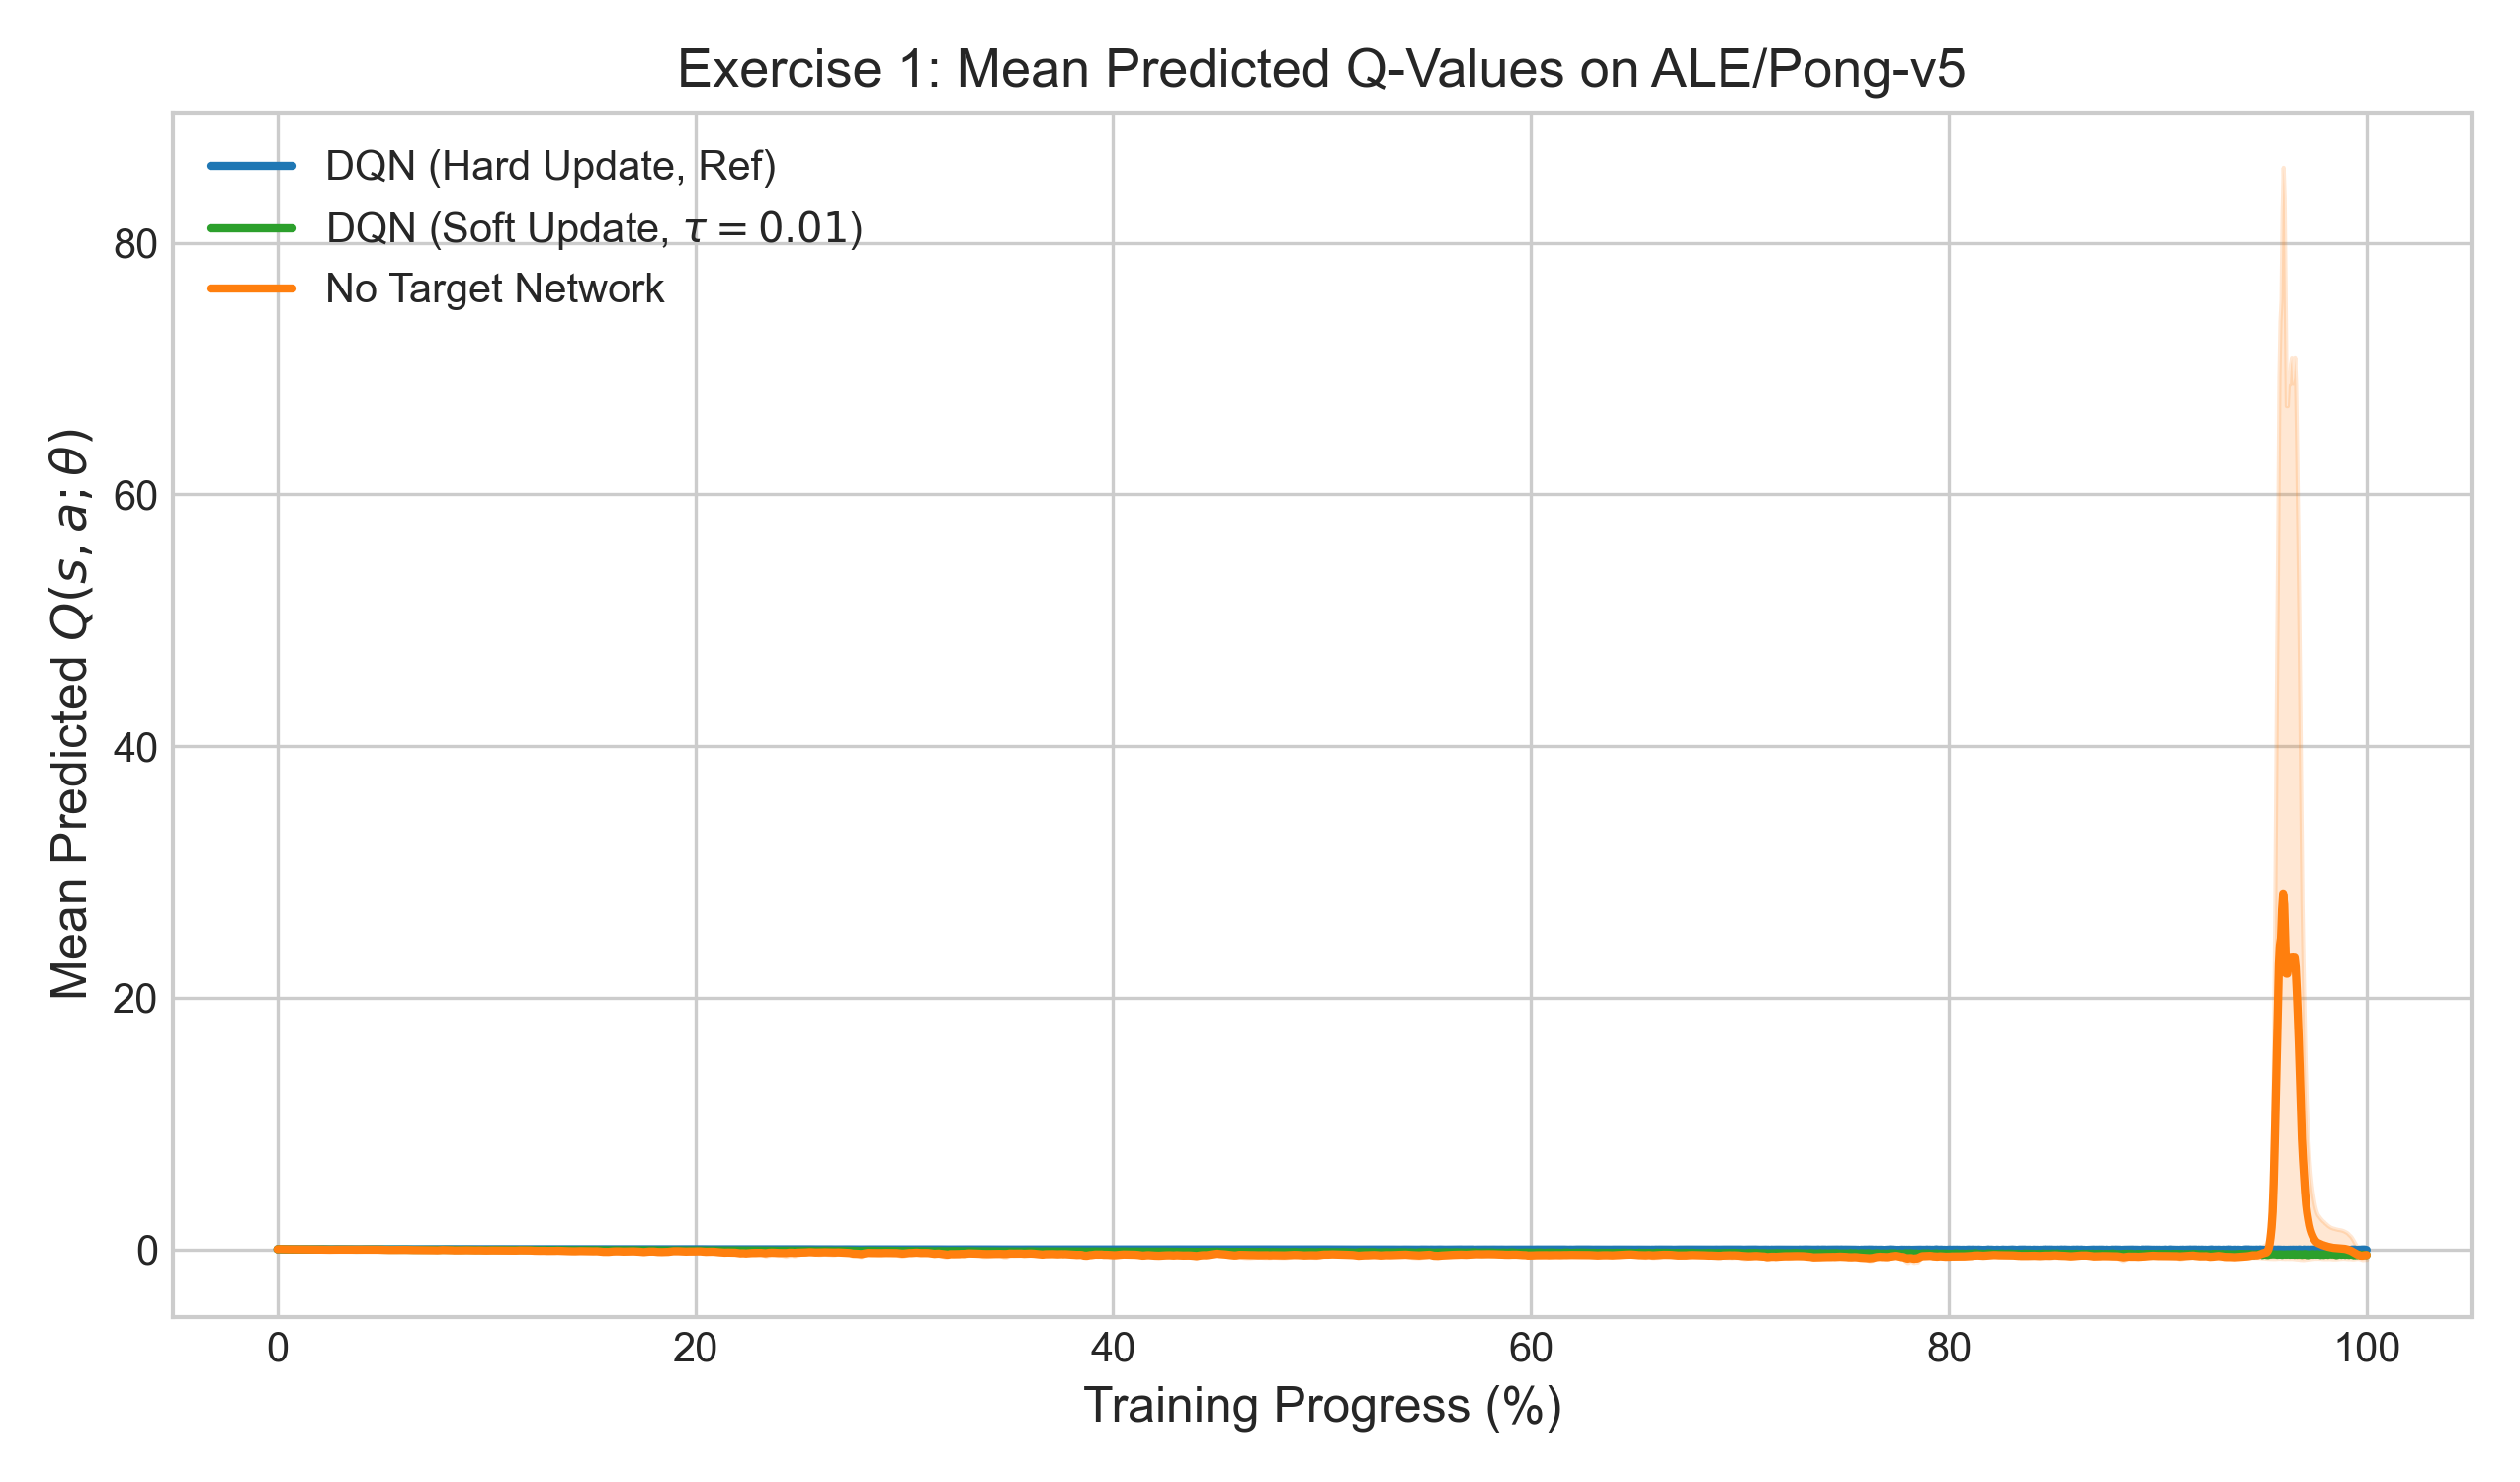

In [ ]:
# Plot Predicted Q-Values During Training 
import os
from IPython.display import Image, display
display(Image(filename=os.path.join("figures", "ex1_pong_q_values.png")))


### 2. Empirical Findings & Ablation Analysis for `ALE/Pong-v5`
1. **Target Network Effect (Reference vs No Target Network)**:
   - Without a target network ($Q(s', a'; \theta)$ used for targets), updates suffer from non-stationary feedback loops (the *moving target problem*). As shown in the Q-value curves, predicted values oscillate rapidly or explode, leading to unstable policy optimization.
   - The periodic hard update (or soft Polyak update) freezes the target distribution, ensuring regression stability and theoretical contraction properties under the Bellman operator.
2. **Replay Buffer Effect (Reference vs No Experience Replay)**:
   - Removing experience replay forces the online network to train on temporally correlated consecutive transitions from the current trajectory.
   - This severely violates the i.i.d. assumption necessary for stochastic gradient descent, causing catastrophic forgetting of earlier state distributions and drastic variance across random seeds.
3. **Hard Update vs Soft Update**:
   - Soft updates ($\tau = 0.01$) provide smoother gradient flows with reduced step-discontinuities compared to hard periodic updates ($C=100/250/1000$), yielding comparable or slightly faster convergence with tighter min-max seed variance.
